<a href="https://colab.research.google.com/github/Rubal-code/DEEP-LEARNING/blob/main/01_pytorch_fundamentals_video5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
what_were_covering = {
    1:"data (prepare and load)",
    2:"build model",
    3:"fitting the model to data (training)",
    4:"making predictions and evaluating the model (inference)",
    5:"saving and loading a trained model",
    6:"putting it all together"
}
what_were_covering

{1: 'data (prepare and load)',
 2: 'build model',
 3: 'fitting the model to data (training)',
 4: 'making predictions and evaluating the model (inference)',
 5: 'saving and loading a trained model',
 6: 'putting it all together'}

In [3]:
import torch
from torch import nn # nn contains the all pytorch's building blocks for making the neural network
import matplotlib.pyplot as plt

torch.__version__

'2.14.1+cpu'

In [4]:
# create known parameters
weight = 0.7
bias = 0.3
# create
start = 0
end = 1
step = 0.02
X=torch.arange(start=start,end=end,step=step).unsqueeze(dim=1)
y=weight*X+bias
X[:10],y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [5]:
len(X), len(y)

(50, 50)

### spliting the data into training and testing data


In [6]:
train_split=int(0.7 * len(X))
X_train,y_train=X[:train_split],y[:train_split]
X_test,y_test=X[train_split:],y[train_split:]

In [7]:
len(X_train),len(y_train),len(X_test),len(y_test)

(35, 35, 15, 15)

In [8]:
def plot_predictions(
                    train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None
                    ):
  plt.figure(figsize=(10,7))
  plt.scatter(train_data,train_labels,c="b",s=4,label="training data")
  plt.scatter(test_data,test_labels,c="g",s=4,label="testing data")
  if predictions is not None:
    plt.scatter(test_data,predictions,c="r",s=4,label="predictions")


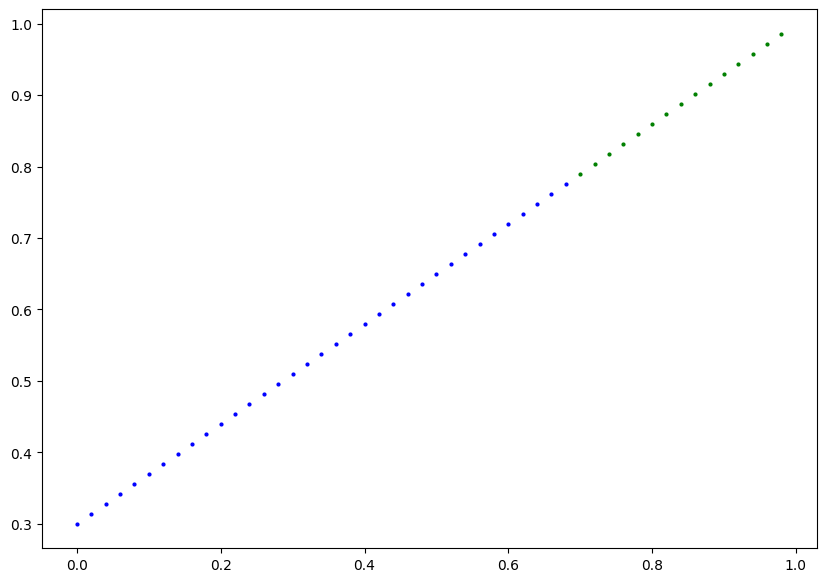

In [9]:
plot_predictions()

In [16]:
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(
        1,
        requires_grad=True,
        dtype=torch.float
    ))
    self.bias = nn.Parameter(torch.randn(
        1,
        requires_grad=True,
        dtype=torch.float
    ))
  # forward method to define the computation in the model
  def forward(self,x:torch.Tensor)->torch.Tensor:
    return self.weights * x + self.bias


In [15]:
lr=LinearRegressionModel()
lr.state_dict()

OrderedDict([('weights', tensor([0.2040])), ('bias', tensor([0.6323]))])

### pytorch model building essentials

* torch.nn - contains all the buildings for computational graph (a neural network is considered as computational graph)
* torch.nn.Parameter - what parameters should our model try and learn, often a pytorch layer from torch.nn will set for us
* torch.nn.Module - the base class for all neural networks modules , if you subclass it, you should overwrite the forward()
* torch.optim - this is where optimizersin pytorch live , they will help with the gradient descent
* forward() - this method defines what happpens in forward computation
* Dataset – Stores and accesses your data.
* DataLoader – Loads data in batches and makes it easier to train models.

In [19]:
torch.manual_seed(42)
# create an instance of the model
model_0 = LinearRegressionModel()

list(model_0.parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [21]:
# list named parameters
model_0.state_dict()      # i want to get closer to the weigth and bias which i have already intialized

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

# lets calculate the predictions using `torch.inference_mode()`
*To check our models predictive power , lets see how well it predicts `y_test` on based on `x_test`
* when we pass the data it will gone throught the forward pass


In [31]:
# make the predictions with model
with torch.inference_mode():
  y_pred = model_0(X_test)
y_pred
# you can also do it with like this torch.no_grad(), however the torch.inference_mode ()is prefered we do this things beacuse it makes the prediction faster and it discards the gradients and usefull things during the training phasee which we had use
# with torch.no_grad():
  #y_pred = model_0(y_test)
# y_pred


tensor([[0.3645],
        [0.3712],
        [0.3780],
        [0.3847],
        [0.3914],
        [0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [27]:
y_test

tensor([[0.7900],
        [0.8040],
        [0.8180],
        [0.8320],
        [0.8460],
        [0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

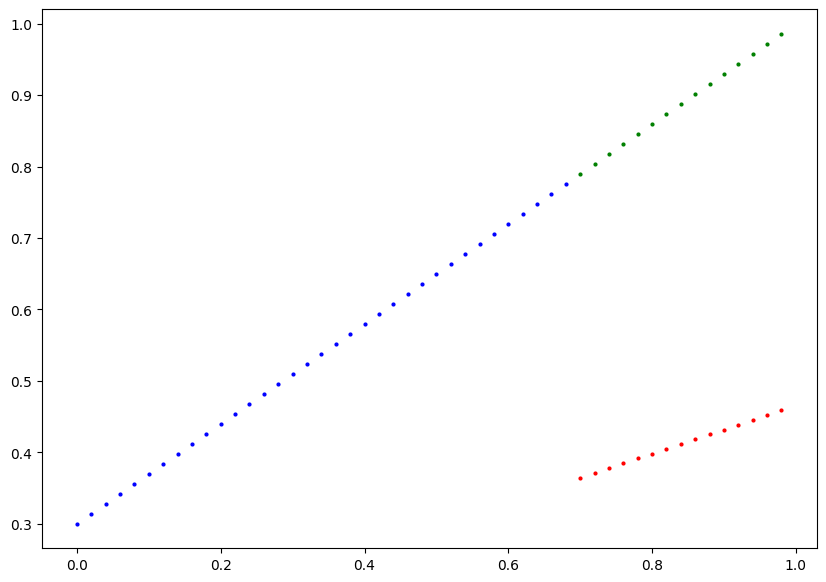

In [29]:
plot_predictions(predictions = y_pred)